In [1]:
import sys
import subprocess

# Fuerza la instalación en el Python exacto del kernel actual
subprocess.check_call([sys.executable, "-m", "pip", "install", "sqlalchemy", "pymysql", "cryptography", "matplotlib", "seaborn"])
print("¡Librerías instaladas correctamente en:", sys.executable)

¡Librerías instaladas correctamente en: c:\Users\salga\AppData\Local\Programs\Python\Python313\python.exe


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine

# Configuración visual
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (11, 5)

# Conexión al Data Warehouse en MySQL
USUARIO = "root"
PASSWORD = "password"  # <-- Pon aquí tu clave de MySQL
HOST = "localhost"
PUERTO = "3306"
BASE_DATOS = "dw_ciencia_ficcion"

engine = create_engine(f"mysql+pymysql://{USUARIO}:{PASSWORD}@{HOST}:{PUERTO}/{BASE_DATOS}")
print("Conexión lista al Data Warehouse:", BASE_DATOS)

Conexión lista al Data Warehouse: dw_ciencia_ficcion


In [4]:
# ==============================================================================
# PREGUNTA 1: Rendimiento, Calidad Ponderada y Engagement por Subgénero
# ==============================================================================
sql_pregunta_1 = """
SELECT 
    dimension_subgenero.nombre_subgenero AS subgenero,
    COUNT(tabla_hechos_libros_subgenero.id_libro) AS total_libros_en_subgenero,
    SUM(tabla_hechos_libros_subgenero.cantidad_votos) AS total_votos,
    SUM(tabla_hechos_libros_subgenero.cantidad_resenas) AS total_resenas,
    ROUND(AVG(tabla_hechos_libros_subgenero.calificacion_promedio), 2) AS calificacion_simple,
    ROUND(
        SUM(tabla_hechos_libros_subgenero.calificacion_promedio * tabla_hechos_libros_subgenero.cantidad_votos) 
        / NULLIF(SUM(tabla_hechos_libros_subgenero.cantidad_votos), 0), 
    2) AS calificacion_ponderada,
    ROUND(
        (SUM(tabla_hechos_libros_subgenero.cantidad_resenas) / NULLIF(SUM(tabla_hechos_libros_subgenero.cantidad_votos), 0)) * 1000, 
    2) AS resenas_por_cada_1000_votos
FROM tabla_hechos_libros_subgenero
INNER JOIN dimension_subgenero 
    ON tabla_hechos_libros_subgenero.id_subgenero = dimension_subgenero.id_subgenero
GROUP BY dimension_subgenero.nombre_subgenero
ORDER BY total_votos DESC;
"""

df_p1 = pd.read_sql(sql_pregunta_1, engine)
print("=== RESULTADO PREGUNTA 1: SUBGÉNEROS ===")
display(df_p1)

# ==============================================================================
# PREGUNTA 2: Top 10 Autores por Calificación Ponderada (Deduplicando Obras)
# ==============================================================================
sql_pregunta_2 = """
WITH obras_unicas_por_autor AS (
    SELECT 
        tabla_hechos_libros_subgenero.id_libro,
        tabla_hechos_libros_subgenero.id_autor,
        MAX(tabla_hechos_libros_subgenero.calificacion_promedio) AS calificacion_libro,
        MAX(tabla_hechos_libros_subgenero.cantidad_votos) AS votos_libro,
        MAX(tabla_hechos_libros_subgenero.cantidad_resenas) AS resenas_libro,
        COUNT(DISTINCT tabla_hechos_libros_subgenero.id_subgenero) AS cantidad_subgeneros_libro
    FROM tabla_hechos_libros_subgenero
    GROUP BY 
        tabla_hechos_libros_subgenero.id_libro, 
        tabla_hechos_libros_subgenero.id_autor
)
SELECT 
    dimension_autor.nombre_autor AS autor,
    COUNT(obras_unicas_por_autor.id_libro) AS obras_unicas_publicadas,
    SUM(obras_unicas_por_autor.votos_libro) AS votos_reales_acumulados,
    SUM(obras_unicas_por_autor.resenas_libro) AS resenas_reales_acumuladas,
    ROUND(AVG(obras_unicas_por_autor.calificacion_libro), 2) AS calificacion_simple,
    ROUND(
        SUM(obras_unicas_por_autor.calificacion_libro * obras_unicas_por_autor.votos_libro) 
        / NULLIF(SUM(obras_unicas_por_autor.votos_libro), 0), 
    2) AS calificacion_ponderada
FROM obras_unicas_por_autor
INNER JOIN dimension_autor 
    ON obras_unicas_por_autor.id_autor = dimension_autor.id_autor
GROUP BY dimension_autor.nombre_autor
HAVING COUNT(obras_unicas_por_autor.id_libro) >= 5 
   AND SUM(obras_unicas_por_autor.votos_libro) >= 100000
ORDER BY calificacion_ponderada DESC, votos_reales_acumulados DESC
LIMIT 10;
"""

df_p2 = pd.read_sql(sql_pregunta_2, engine)
print("\n=== RESULTADO PREGUNTA 2: TOP 10 AUTORES CONSISTENTES ===")
display(df_p2)

# ==============================================================================
# PREGUNTA 3: Evolución por Década (desde 1950) y Dominio de Idioma
# ==============================================================================
sql_pregunta_3 = """
WITH obras_unicas_tiempo AS (
    SELECT 
        tabla_hechos_libros_subgenero.id_libro,
        tabla_hechos_libros_subgenero.id_tiempo,
        tabla_hechos_libros_subgenero.id_idioma,
        MAX(tabla_hechos_libros_subgenero.calificacion_promedio) AS calificacion_libro,
        MAX(tabla_hechos_libros_subgenero.cantidad_votos) AS votos_libro,
        MAX(tabla_hechos_libros_subgenero.cantidad_resenas) AS resenas_libro
    FROM tabla_hechos_libros_subgenero
    GROUP BY 
        tabla_hechos_libros_subgenero.id_libro,
        tabla_hechos_libros_subgenero.id_tiempo,
        tabla_hechos_libros_subgenero.id_idioma
)
SELECT 
    dimension_tiempo_publicacion.decada AS decada_publicacion,
    COUNT(obras_unicas_tiempo.id_libro) AS cantidad_obras_unicas,
    SUM(CASE WHEN dimension_idioma.idioma_edicion = 'English' THEN 1 ELSE 0 END) AS obras_en_ingles,
    ROUND(
        (SUM(CASE WHEN dimension_idioma.idioma_edicion = 'English' THEN 1 ELSE 0 END) / COUNT(obras_unicas_tiempo.id_libro)) * 100, 
    1) AS porcentaje_ingles,
    SUM(obras_unicas_tiempo.votos_libro) AS total_votos_decada,
    ROUND(AVG(obras_unicas_tiempo.votos_libro), 0) AS promedio_votos_por_libro,
    ROUND(
        SUM(obras_unicas_tiempo.calificacion_libro * obras_unicas_tiempo.votos_libro) 
        / NULLIF(SUM(obras_unicas_tiempo.votos_libro), 0), 
    2) AS calificacion_ponderada_decada
FROM obras_unicas_tiempo
INNER JOIN dimension_tiempo_publicacion 
    ON obras_unicas_tiempo.id_tiempo = dimension_tiempo_publicacion.id_tiempo
INNER JOIN dimension_idioma 
    ON obras_unicas_tiempo.id_idioma = dimension_idioma.id_idioma
WHERE dimension_tiempo_publicacion.anio_publicacion >= 1950
GROUP BY dimension_tiempo_publicacion.decada
ORDER BY dimension_tiempo_publicacion.decada ASC;
"""

df_p3 = pd.read_sql(sql_pregunta_3, engine)
print("\n=== RESULTADO PREGUNTA 3: EVOLUCIÓN POR DÉCADA (1950 - PRESENTE) ===")
display(df_p3)

=== RESULTADO PREGUNTA 1: SUBGÉNEROS ===


,subgenero,total_libros_en_subgenero,total_votos,total_resenas,calificacion_simple,calificacion_ponderada,resenas_por_cada_1000_votos
0,alternate_universe,1247,178673631.0,8620223.0,4.04,4.17,48.2
1,dystopia,1242,106697816.0,6165525.0,3.91,4.07,57.8
2,apocalyptic,1248,82506031.0,4563078.0,3.93,4.06,55.3
3,alternate_history,1249,62383287.0,3427821.0,3.85,4.09,54.9
4,cyberpunk,1244,49042035.0,2229269.0,3.89,4.14,45.5
5,hard,1246,44941419.0,2065607.0,3.91,4.12,46.0
6,time_travel,1248,33399842.0,1909407.0,3.92,4.09,57.2
7,aliens,1250,28095543.0,1635058.0,3.97,4.10,58.2
8,robots,1250,27663026.0,1702194.0,3.90,4.12,61.5
9,steampunk,1250,26339902.0,1692761.0,3.87,4.07,64.3



=== RESULTADO PREGUNTA 2: TOP 10 AUTORES CONSISTENTES ===


,autor,obras_unicas_publicadas,votos_reales_acumulados,resenas_reales_acumuladas,calificacion_simple,calificacion_ponderada
0,Hiromu Arakawa,26,365771.0,6764.0,4.60,4.56
1,J.K. Rowling,8,23950035.0,436908.0,4.49,4.52
2,Hajime Isayama,12,278664.0,7259.0,4.48,4.46
3,Brandon Sanderson,22,2472669.0,172420.0,4.26,4.40
4,George R.R. Martin,14,4791904.0,149072.0,4.04,4.39
5,Sarah J. Maas,17,3798041.0,352335.0,4.36,4.37
6,J.R.R. Tolkien,6,7653204.0,115877.0,4.34,4.35
7,Pierce Brown,5,613729.0,55748.0,4.36,4.35
8,Rick Riordan,9,6797092.0,229346.0,4.37,4.34
9,Ilona Andrews,32,1053898.0,72104.0,4.32,4.32



=== RESULTADO PREGUNTA 3: EVOLUCIÓN POR DÉCADA (1950 - PRESENTE) ===


,decada_publicacion,cantidad_obras_unicas,obras_en_ingles,porcentaje_ingles,total_votos_decada,promedio_votos_por_libro,calificacion_ponderada_decada
0,1950s,111,107.0,96.4,17398958.0,156747.0,4.12
1,1960s,156,149.0,95.5,7858942.0,50378.0,4.03
2,1970s,203,197.0,97.0,6442020.0,31734.0,4.12
3,1980s,502,488.0,97.2,14327981.0,28542.0,4.10
4,1990s,977,939.0,96.1,37534401.0,38418.0,4.24
5,2000s,2161,2063.0,95.5,85350787.0,39496.0,4.13
6,2010s,6579,5958.0,90.6,89384332.0,13586.0,4.07
7,2020s,290,239.0,82.4,1751770.0,6041.0,4.04


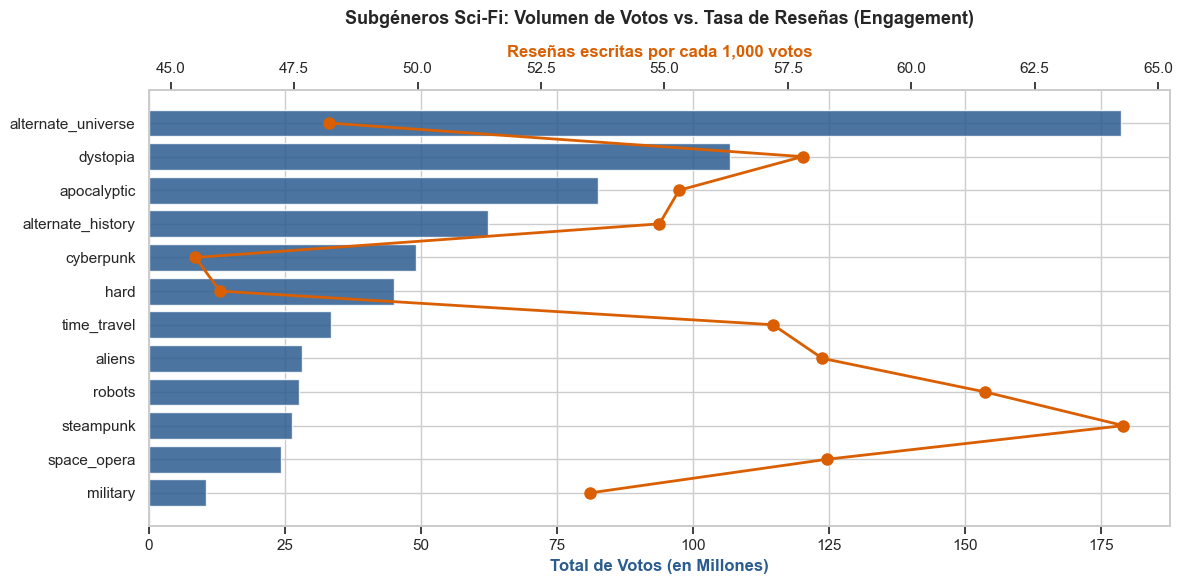

In [5]:
# ==============================================================================
# GRÁFICO 1: Posicionamiento de Subgéneros (Volumen vs. Engagement vs. Calidad)
# ==============================================================================
fig, ax1 = plt.subplots(figsize=(12, 6))

df_p1_sorted = df_p1.sort_values("total_votos", ascending=True)
bars = ax1.barh(df_p1_sorted["subgenero"], df_p1_sorted["total_votos"] / 1e6, color="#2b5c8f", alpha=0.85, label="Total Votos (Millones)")
ax1.set_xlabel("Total de Votos (en Millones)", color="#2b5c8f", fontweight="bold")
ax1.set_title("Subgéneros Sci-Fi: Volumen de Votos vs. Tasa de Reseñas (Engagement)", fontsize=13, fontweight="bold", pad=15)

ax2 = ax1.twiny()
ax2.plot(df_p1_sorted["resenas_por_cada_1000_votos"], df_p1_sorted["subgenero"], color="#d95f02", marker="o", linewidth=2, markersize=8, label="Reseñas por cada 1,000 votos")
ax2.set_xlabel("Reseñas escritas por cada 1,000 votos", color="#d95f02", fontweight="bold")
ax2.grid(False)

plt.tight_layout()
plt.show()

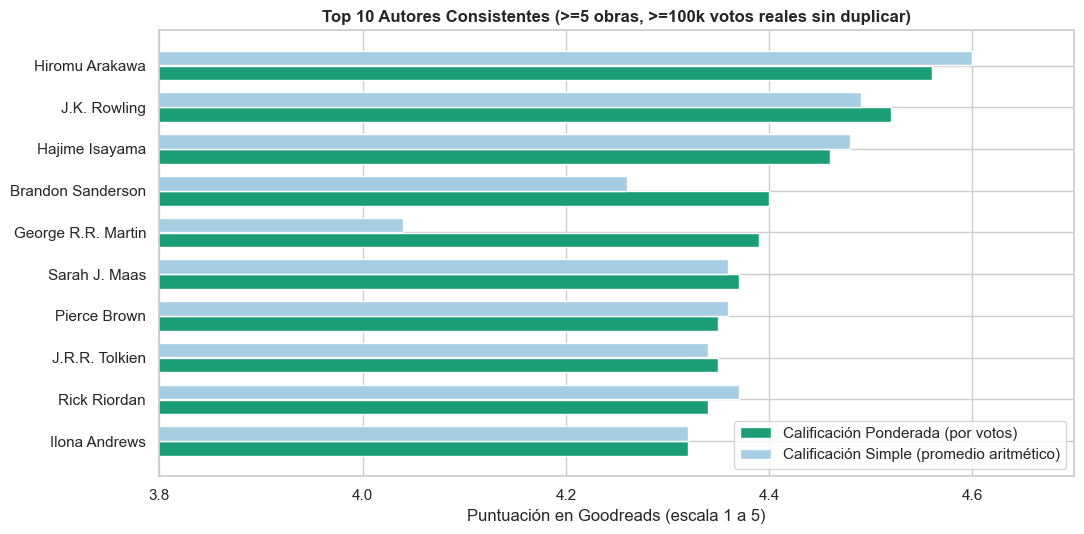

In [6]:
# ==============================================================================
# GRÁFICO 2: Top 10 Autores - Calificación Ponderada vs. Calificación Simple
# ==============================================================================
fig, ax = plt.subplots(figsize=(11, 5.5))

df_p2_sorted = df_p2.sort_values("calificacion_ponderada", ascending=True)
y_pos = range(len(df_p2_sorted))

ax.barh([y - 0.18 for y in y_pos], df_p2_sorted["calificacion_ponderada"], height=0.35, color="#1b9e77", label="Calificación Ponderada (por votos)")
ax.barh([y + 0.18 for y in y_pos], df_p2_sorted["calificacion_simple"], height=0.35, color="#a6cee3", label="Calificación Simple (promedio aritmético)")

ax.set_yticks(y_pos)
ax.set_yticklabels(df_p2_sorted["autor"])
ax.set_xlim(3.8, 4.7)
ax.set_xlabel("Puntuación en Goodreads (escala 1 a 5)")
ax.set_title("Top 10 Autores Consistentes (>=5 obras, >=100k votos reales sin duplicar)", fontsize=12, fontweight="bold")
ax.legend(loc="lower right")

plt.tight_layout()
plt.show()

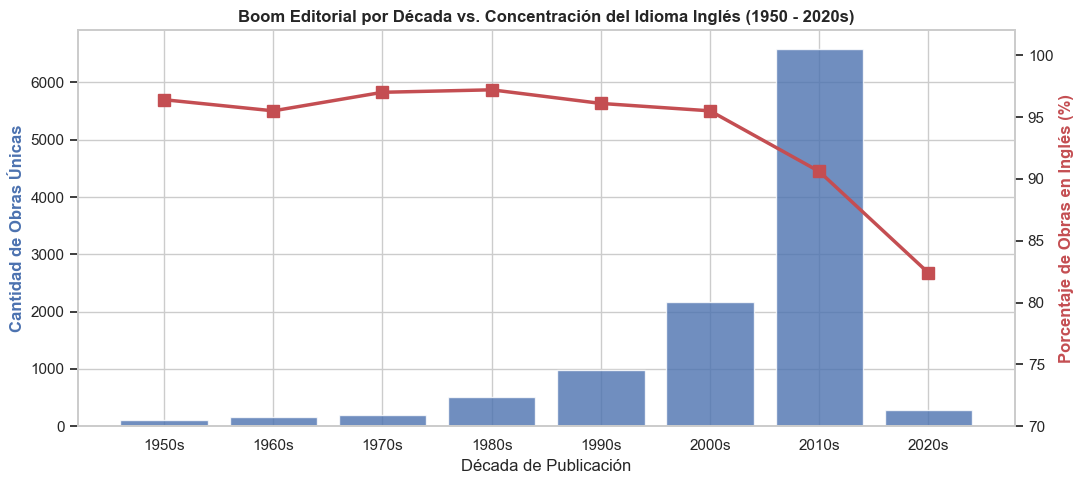

In [7]:
# ==============================================================================
# GRÁFICO 3: Evolución Histórica por Década (Obras Únicas y % en Inglés)
# ==============================================================================
fig, ax1 = plt.subplots(figsize=(11, 5))

ax1.bar(df_p3["decada_publicacion"], df_p3["cantidad_obras_unicas"], color="#4c72b0", alpha=0.8, label="Obras Únicas Publicadas")
ax1.set_ylabel("Cantidad de Obras Únicas", color="#4c72b0", fontweight="bold")
ax1.set_xlabel("Década de Publicación")
ax1.set_title("Boom Editorial por Década vs. Concentración del Idioma Inglés (1950 - 2020s)", fontsize=12, fontweight="bold")

ax2 = ax1.twinx()
ax2.plot(df_p3["decada_publicacion"], df_p3["porcentaje_ingles"], color="#c44e52", marker="s", linewidth=2.5, markersize=8, label="% Obras en Inglés")
ax2.set_ylabel("Porcentaje de Obras en Inglés (%)", color="#c44e52", fontweight="bold")
ax2.set_ylim(70, 102)
ax2.grid(False)

plt.tight_layout()
plt.show()